# Check an interpolated field before calling it a twin

**Learning question:** Can bilinear interpolation reproduce a planar synthetic field, and what does that check leave untested?

Thirty-two complete synthetic experiments introduce Destination Earth architecture, grids, interpolation, validation, ensembles and bounded service handoffs.

This introductory calculation is an original **synthetic** teaching exercise. Full source lessons and their actual data status are separately described below.


## Predict before running

Bilinear interpolation blends four corner values using relative coordinates inside a rectangle. Its weights must sum to one. An affine plane gives an independent exact oracle; agreement tests the interpolation arithmetic without validating the physics, observations or an operational Digital Twin.


In [1]:
from IPython.display import SVG, display
from html import escape

def svg(body, title, description, width=760, height=330):
    label = escape(title, quote=True)
    display(SVG(f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{label}"><title>{escape(title)}</title><desc>{escape(description)}</desc><rect width="100%" height="100%" fill="#f5f5ef" rx="12"/>{body}</svg>'))

def bars(values, title, unit):
    print(title + ' | ' + unit + ':', {k:round(v,3) for k,v in values.items()})
    n = len(values)
    height = max(250, 82 + n*36)
    maximum = max(max(values.values()), 1)
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18" fill="#123c45">{escape(title)}</text>'
    for i,(key,value) in enumerate(values.items()):
        y=58+i*36
        body += f'<text x="22" y="{y+17}" font-family="sans-serif" font-size="13">{escape(str(key))}</text><rect x="205" y="{y}" width="{max(0,value)/maximum*440:.2f}" height="23" rx="3" fill="#16756b"/><text x="{213+max(0,value)/maximum*440:.2f}" y="{y+17}" font-family="sans-serif" font-size="13">{value:.2f}</text>'
    body += f'<text x="205" y="{height-15}" font-family="sans-serif" font-size="12">zero baseline · {escape(unit)}</text>'
    svg(body, title, 'Values are printed as a text alternative; consult the chart title for data status.', height=height)

def grid(values, columns, title):
    print(title + ':', [round(v,3) for v in values])
    maximum = max(max(values),1)
    size = 54
    body = f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text>'
    for i,v in enumerate(values):
        x=25+(i%columns)*size; y=52+(i//columns)*size
        light=92-50*v/maximum
        body += f'<rect x="{x}" y="{y}" width="50" height="50" fill="hsl(169,45%,{light:.1f}%)" stroke="#123c45"/><text x="{x+25}" y="{y+29}" text-anchor="middle" font-family="sans-serif" font-size="14" fill="#061c21">{v:.1f}</text>'
    svg(body,title,'Synthetic grid with values printed in each cell; no actual boundaries.',height=max(220,70+((len(values)+columns-1)//columns)*size))

def lines(series, title, xunit, yunit):
    print(title + ':', {k:[round(v,3) for v in vs] for k,vs in series.items()})
    maximum=max(max(vs) for vs in series.values()) or 1
    body=f'<text x="22" y="30" font-family="sans-serif" font-size="18">{escape(title)}</text><path d="M55 55V265H710" fill="none" stroke="#123c45"/>'
    for j,(name,vs) in enumerate(series.items()):
        color=['#16756b','#a34712','#41449c'][j%3]
        pts=' '.join(f'{55+i*650/max(1,len(vs)-1):.1f},{265-v*200/maximum:.1f}' for i,v in enumerate(vs))
        body+=f'<polyline points="{pts}" fill="none" stroke="{color}" stroke-width="3"/><text x="{60+j*220}" y="310" font-family="sans-serif" font-size="13" fill="{color}">{escape(name)}</text>'
    body+=f'<text x="55" y="288" font-family="sans-serif" font-size="12">{escape(xunit)} → · {escape(yunit)} ↑ · y starts at zero</text>'
    svg(body,title,'Synthetic series; printed values are the text alternative.')


Synthetic bilinear result: 24.999999999999996 ; independent plane oracle: 25
Weight sum: 1.0 ; absolute error: 3.552713678800501e-15
Synthetic interpolation contributions | dimensionless weight: {'SW': 0.24, 'SE': 0.56, 'NW': 0.06, 'NE': 0.14}


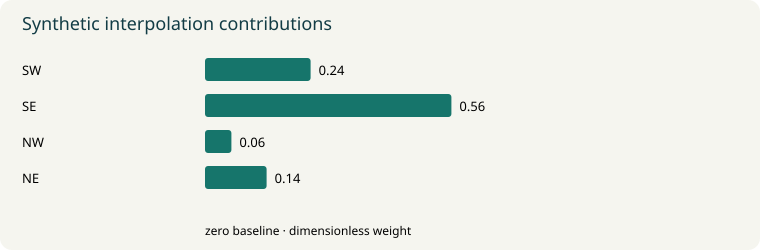

In [2]:
south, north, west, east = 0, 10, 0, 10
latitude, longitude = 2, 7
tx = (longitude-west)/(east-west)
ty = (latitude-south)/(north-south)
weights = {'SW':(1-tx)*(1-ty),'SE':tx*(1-ty),'NW':(1-tx)*ty,'NE':tx*ty}
corners = {'SW':0,'SE':30,'NW':20,'NE':50}  # synthetic plane 3*lon+2*lat
interpolated = sum(weights[key]*corners[key] for key in weights)
oracle = 3*longitude+2*latitude
print('Synthetic bilinear result:', interpolated, '; independent plane oracle:', oracle)
print('Weight sum:', sum(weights.values()), '; absolute error:', abs(interpolated-oracle))
assert abs(interpolated-25) < 1e-12 and abs(sum(weights.values())-1) < 1e-12
bars(weights, 'Synthetic interpolation contributions', 'dimensionless weight')


## Interpret the result

At latitude 2, longitude 7, the field is 25 synthetic units, with weights SW 0.24, SE 0.56, NW 0.06 and NE 0.14. A successful plane check does not establish validity at discontinuities, across longitude seams, outside the rectangle, or with missing corners. Neither interpolation nor a polished globe makes these values observations.

## Change one thing

Move the target to a corner and then the centre. Add a bounds check before trying extrapolation. Replace one corner with a missing value and write an explicit policy rather than silently substituting zero. Continue with source lessons 11 and 13 to compare interpolation and forecast verification.


## Source course and scientific boundaries

All 32 source notebooks and earthlab.py are bundled, with the coverage/access guides and original BibTeX reference. Browser setup requests numpy, matplotlib, pandas, xarray and ipywidgets. Five optional widget branches require the source frontend; static plots and printed values are alternatives. Fresh native calculations and actual browser graphics are separate checks. Real DTE, Climate DT, Weather-Induced Extremes DT, Polytope, Data Lake, Earthkit, ML and HPC services remain external authorized continuations.

[Complete local course guide](../../courses/destination-earth-digital-twin/index.ipynb) · [Notebook library](../../notebook-library.ipynb)


## Sources, attribution and limits

[Reviewed source README](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/README.md) · [Source repository](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin)

Independent teaching companion; European Union initiative implemented by ECMWF, ESA and EUMETSAT, with no endorsement implied. All default numerical inputs are original synthetic equations/seeded arrays, not observations, operational forecasts or Digital Twin outputs. Code MIT; original prose/generated numerical data/artwork CC BY 4.0, with repository attribution and adaptation notice retained. Original splash generation provenance credits OpenAI image-generation assistance. ECMWF Generation 2 Climate DT DOI 10.21957/79c6af3105 is cited as metadata context: the dataset is not used. No accounts, credentials or real service/model calls occur.

- [Read source Book](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/book/) — Source-route reviewed; HTTP entry not freshly checked
- [Run source Lab](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=01-system.ipynb) — Source-route reviewed; HTTP entry not freshly checked
- [Open source portal](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/) — Source-route reviewed; HTTP entry not freshly checked
- [Explore synthetic map gallery](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/gallery/map/) — Source-route reviewed; HTTP entry not freshly checked
- [Explore synthetic terrain gallery](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/gallery/terrain/) — Source-route reviewed; HTTP entry not freshly checked
- [Explore synthetic globe gallery](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/gallery/globe/) — Source-route reviewed; HTTP entry not freshly checked
- [Explore synthetic dashboard](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/gallery/dashboard/) — Source-route reviewed; HTTP entry not freshly checked
- [Explore synthetic vector flow](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/gallery/flow/) — Source-route reviewed; HTTP entry not freshly checked
- [Explore synthetic comparison](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/gallery/compare/) — Source-route reviewed; HTTP entry not freshly checked

[Central references](../../references.ipynb)


## Browser GIS pathway

**Geographic question:** Can a synthetic interpolation check support a bounded map handoff without claiming a real Digital Twin product?

**Data readiness (O; C continuation):** All 32 source lessons use original equations and seeded synthetic arrays. earthlab.py and the access guide are bundled; no real DestinE output or observational dataset is packaged.

**Start from the chapter evidence:** [interpolation](../../courses/destination-earth-digital-twin/11-interpolation.ipynb) · [validation](../../courses/destination-earth-digital-twin/13-verification.ipynb) · [official access boundary](https://github.com/jltobias/JupyterLite-Learning-Atlas/blob/main/content/courses/destination-earth-digital-twin/book/official-access.md) (`courses/destination-earth-digital-twin/book/official-access.md`)

- **[RustGIS Web](https://web.rustgis.app/):** Build a tiny explicitly synthetic WGS84 fixture from the exercise only after declaring coordinates and units; compare one interpolated value to the plane oracle before exporting.
- **[GeoLibre Web](https://web.geolibre.app/):** Import that same synthetic fixture and compare feature IDs, 25-unit oracle value and missingness. Actual authorized DestinE exports need their own provenance and service terms.

**Handoff:** Use the [GIS workbench](../../gis-workbench.ipynb) to validate/export an attributed WGS84 layer. Download the GeoJSON, method record and review prompt from `exports/`, then import through the chosen app’s file picker. Compare `_atlas_source_id` (or source `GEOID`) with the original IDs; app-generated internal IDs may differ. Return changed results by explicit upload. Apps and the notebook share no files or kernel state. Practice-only Census data remain Fresno 2020, never this subject’s observations.

**Optional AI prompt (approved subject evidence only):** “Identify which supplied results are synthetic arithmetic checks and which claims would require independent observations or a real DestinE service. Cite supplied feature IDs/fields, separate observations from assumptions, abstain when evidence is missing, and propose one falsifiable check.” For the common practice package, use its generated schema/summary prompt instead. A human-written answer completes the same task.

**GeoAI opportunity:** A later learned surrogate needs independent observations, spatial/time holdouts and uncertainty; a Canvas globe or interpolation is not a validated twin. Any later fitted exercise must name target/features and spatial/temporal support, reserve a spatial/temporal holdout, inspect leakage and uncertainty, and state evidence that would disprove the interpretation. Styling, thresholds, schema checks and chat alone are not model fitting.

**Human evidence check:** Reconcile IDs, bilinear weights summing to one, units, synthetic labels and explicit exclusion of real-service certification. Ask the intended reader which decision the map supports; change one legend, filter or annotation, then recheck interpretation against the same IDs and values.

**Continue:** [cross-tool guide and optional Ollama setup](../../browser-gis.ipynb) · [RustGIS assistance](../../courses/rustgis/07_ollama_assistance.ipynb) · [GeoLibre setup](../../courses/geolibre-geoai/18_ollama_geolibre_setup.ipynb) · [chat-to-map](../../courses/geolibre-geoai/19_ollama_chat_to_map.ipynb) · [evidence review](../../courses/geolibre-geoai/20_ollama_evidence_review.ipynb). AI is optional; no service or model is called by this pathway.
